In [1]:
%matplotlib qt

Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none


In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [3]:
DATA_DIR = Path(r"C:\College Work\Project-1\data\raw")

file_path = DATA_DIR / "H S1 EC.edf"

raw = mne.io.read_raw_edf(
    file_path,
    preload=True,
    verbose=False
)

print(raw)

<RawEDF | H S1 EC.edf, 22 x 76800 (300.0 s), ~12.9 MiB, data loaded>


In [4]:
scalp_channels = [
    "EEG Fp1-LE",
    "EEG F3-LE",
    "EEG C3-LE",
    "EEG P3-LE",
    "EEG O1-LE",
    "EEG F7-LE",
    "EEG T3-LE",
    "EEG T5-LE",
    "EEG Fz-LE",
    "EEG Fp2-LE",
    "EEG F4-LE",
    "EEG C4-LE",
    "EEG P4-LE",
    "EEG O2-LE",
    "EEG F8-LE",
    "EEG T4-LE",
    "EEG T6-LE",
    "EEG Cz-LE",
    "EEG Pz-LE"
]

In [28]:
def extract_features(file_path):
    #load
    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

   #channel pick
    raw.pick(scalp_channels)

    #bandpass filtering
    raw.filter(
        l_freq=1.0,
        h_freq=45.0,
        verbose=False
    )

    raw.notch_filter(
        freqs=50.0,
        verbose=False
    )

    #epochs
    epochs = mne.make_fixed_length_epochs(
        raw,
        duration=10.0,
        overlap=0.0,
        preload=True,
        verbose=False
    )

   #drop bad epochs
    epochs.drop_bad(
        reject=dict(eeg=150e-6)
    )

    # Calculate PSD
    
    spectrum = epochs.compute_psd(
        method="welch",
        fmin=1,
        fmax=45,
        verbose=False
    )

    psds, freqs = spectrum.get_data(return_freqs=True)

    # Frequency bands
    bands = {
        "delta": (1, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "beta": (13, 30),
        "gamma": (30, 45)
    }

    band_power = {}

    for band_name, (low, high) in bands.items():
        mask = (freqs >= low) & (freqs < high)

        band_power[band_name] = np.trapezoid(
            psds[:, :, mask],
            freqs[mask],
            axis=2
        )

    #Relative band power
    total_power = sum(band_power.values())

    relative_band_power = {}

    for band_name, values in band_power.items():
        relative_band_power[band_name] = values / total_power


    feature_dict = {}

    for band_name, values in relative_band_power.items():

        for channel_idx, channel_name in enumerate(epochs.ch_names):

            clean_channel = (
                channel_name
                .replace("EEG ", "")
                .replace("-LE", "")
            )

            feature_dict[
                f"{clean_channel}_{band_name}_mean"
            ] = values[:, channel_idx].mean()

            feature_dict[
                f"{clean_channel}_{band_name}_std"
            ] = values[:, channel_idx].std()

    return feature_dict

In [29]:
file_path = DATA_DIR / "H S1 EC.edf"

features = extract_features(file_path)

print("Number of features:", len(features))

    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F7-LE', 'EEG Fp2-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F7-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE', 'EEG F8-LE']
3 bad epochs dropped
Number of features: 190


In [30]:
feature_df = pd.DataFrame([features])

print(feature_df.shape)

(1, 190)


In [31]:
file_path = DATA_DIR / "H S1 EO.edf"

features = extract_features(file_path)

print("Number of features:", len(features))

    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F7-LE', 'EEG Fp2-LE', 'EEG F4-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F7-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F3-LE', 'EEG F7-LE', 'EEG Fp2-LE', 'EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG Fp2-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F7-LE', 'EEG Fp2-LE', 'EEG F8-LE']
12 bad epochs dropped
Number of features: 190


In [32]:
file_path = DATA_DIR / "MDD S1 EC.edf"

features = extract_features(file_path)

print("Number of features:", len(features))

    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG F8-LE', 'EEG T4-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F3-LE', 'EEG C3-LE', 'EEG P3-LE', 'EEG O1-LE', 'EEG F7-LE', 'EEG T3-LE', 'EEG T5-LE', 'EEG Fz-LE', 'EEG Fp2-LE', 'EEG F4-LE', 'EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F3-LE', 'EEG C3-LE', 'EEG P3-LE', 'EEG O1-LE', 'EEG F7-LE', 'EEG T3-LE', 'EEG T5-LE', 'EEG Fz-LE', 'EEG Fp2-LE', 'EEG F4-LE', 'EEG C4-LE'

In [10]:
def get_epoch_amplitudes(file_path):
    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

    raw.pick(scalp_channels)

    raw.filter(
        l_freq=1.0,
        h_freq=45.0,
        verbose=False
    )

    raw.notch_filter(
        freqs=50.0,
        verbose=False
    )

    epochs = mne.make_fixed_length_epochs(
        raw,
        duration=10.0,
        overlap=0.0,
        preload=True,
        verbose=False
    )

    # Peak-to-peak amplitude for each epoch/channel
    ptp = np.ptp(
        epochs.get_data(),
        axis=2
    )

    return epochs, ptp

In [11]:
test_files = [
    DATA_DIR / "H S1 EC.edf",
    DATA_DIR / "H S1 EO.edf",
    DATA_DIR / "MDD S1 EC.edf"
]

for file_path in test_files:
    epochs_test, ptp = get_epoch_amplitudes(file_path)

    print("\n", file_path.name)
    print("Epochs:", len(epochs_test))
    print("Maximum PTP:", ptp.max())
    print("Median PTP:", np.median(ptp))


 H S1 EC.edf
Epochs: 30
Maximum PTP: 0.00033579430442480236
Median PTP: 6.144385777952214e-05

 H S1 EO.edf
Epochs: 35
Maximum PTP: 0.00040499654724840433
Median PTP: 5.093258635016737e-05

 MDD S1 EC.edf
Epochs: 30
Maximum PTP: 0.005321249110193608
Median PTP: 6.821167930435486e-05


In [12]:
mdd_epochs, mdd_ptp = get_epoch_amplitudes(
    DATA_DIR / "MDD S1 EC.edf"
)

print("Shape:", mdd_ptp.shape)

Shape: (30, 19)


In [13]:
threshold = 150e-6

bad_per_channel = (mdd_ptp > threshold).sum(axis=0)

for channel, count in zip(mdd_epochs.ch_names, bad_per_channel):
    print(f"{channel}: {count}")

EEG Fp1-LE: 4
EEG F3-LE: 5
EEG C3-LE: 5
EEG P3-LE: 4
EEG O1-LE: 4
EEG F7-LE: 5
EEG T3-LE: 4
EEG T5-LE: 4
EEG Fz-LE: 4
EEG Fp2-LE: 4
EEG F4-LE: 4
EEG C4-LE: 13
EEG P4-LE: 15
EEG O2-LE: 14
EEG F8-LE: 15
EEG T4-LE: 13
EEG T6-LE: 11
EEG Cz-LE: 11
EEG Pz-LE: 10


In [14]:
epoch_max = mdd_ptp.max(axis=1)

for i, value in enumerate(epoch_max):
    print(f"Epoch {i:02d}: {value * 1e6:.2f} µV")

Epoch 00: 974.64 µV
Epoch 01: 1338.65 µV
Epoch 02: 2483.65 µV
Epoch 03: 764.95 µV
Epoch 04: 72.11 µV
Epoch 05: 1290.86 µV
Epoch 06: 1310.34 µV
Epoch 07: 1407.50 µV
Epoch 08: 5321.25 µV
Epoch 09: 1307.80 µV
Epoch 10: 745.37 µV
Epoch 11: 4809.80 µV
Epoch 12: 1391.67 µV
Epoch 13: 45.14 µV
Epoch 14: 1291.03 µV
Epoch 15: 40.46 µV
Epoch 16: 72.40 µV
Epoch 17: 53.25 µV
Epoch 18: 49.70 µV
Epoch 19: 204.85 µV
Epoch 20: 742.91 µV
Epoch 21: 1377.68 µV
Epoch 22: 51.84 µV
Epoch 23: 1233.83 µV
Epoch 24: 4867.42 µV
Epoch 25: 758.75 µV
Epoch 26: 757.05 µV
Epoch 27: 740.21 µV
Epoch 28: 301.00 µV
Epoch 29: 1335.28 µV


In [15]:
mdd_raw = mne.io.read_raw_edf(
    DATA_DIR / "MDD S1 EC.edf",
    preload=True,
    verbose=False
)

mdd_raw.pick(scalp_channels)

mdd_raw.filter(
    l_freq=1.0,
    h_freq=45.0,
    verbose=False
)

mdd_raw.notch_filter(
    freqs=50.0,
    verbose=False
)

<RawEDF | MDD S1 EC.edf, 19 x 77568 (303.0 s), ~11.3 MiB, data loaded>

In [16]:
mdd_epochs = mne.make_fixed_length_epochs(
    mdd_raw,
    duration=10.0,
    overlap=0.0,
    preload=True,
    verbose=False
)

Using matplotlib as 2D backend.


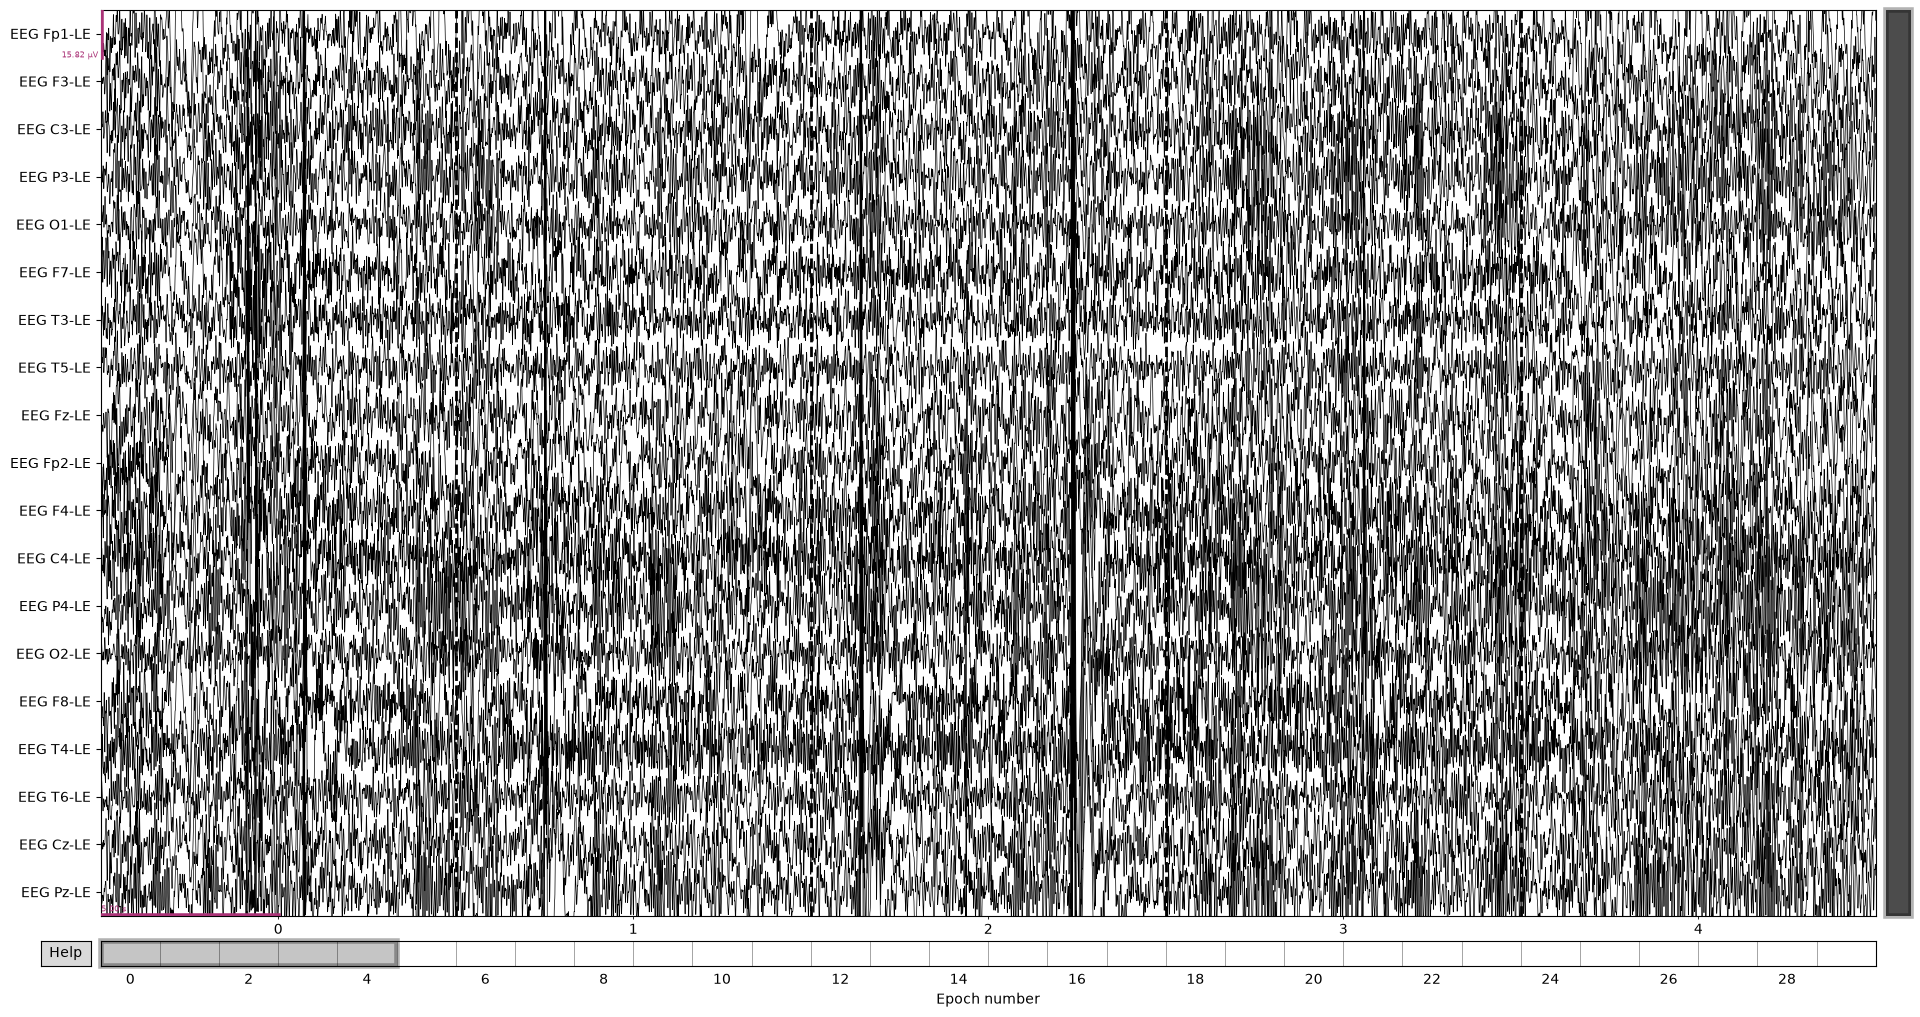

In [17]:
mdd_epochs.plot(
    n_epochs=5,
    n_channels=19,
    scalings="auto"
)

In [18]:
thresholds = [100e-6, 150e-6, 200e-6, 250e-6, 300e-6, 500e-6]

for threshold in thresholds:
    bad_epochs = np.any(mdd_ptp > threshold, axis=1)
    remaining = (~bad_epochs).sum()

    print(
        f"Threshold {threshold * 1e6:>4.0f} µV "
        f"→ {remaining}/30 epochs remain"
    )

Threshold  100 µV → 7/30 epochs remain
Threshold  150 µV → 7/30 epochs remain
Threshold  200 µV → 7/30 epochs remain
Threshold  250 µV → 8/30 epochs remain
Threshold  300 µV → 8/30 epochs remain
Threshold  500 µV → 9/30 epochs remain


In [19]:
threshold = 150e-6

bad_channel_count = np.sum(mdd_ptp > threshold, axis=1)

for i, count in enumerate(bad_channel_count):
    print(f"Epoch {i:02d}: {count}/19 channels above threshold")

Epoch 00: 3/19 channels above threshold
Epoch 01: 2/19 channels above threshold
Epoch 02: 19/19 channels above threshold
Epoch 03: 1/19 channels above threshold
Epoch 04: 0/19 channels above threshold
Epoch 05: 1/19 channels above threshold
Epoch 06: 8/19 channels above threshold
Epoch 07: 8/19 channels above threshold
Epoch 08: 19/19 channels above threshold
Epoch 09: 8/19 channels above threshold
Epoch 10: 2/19 channels above threshold
Epoch 11: 19/19 channels above threshold
Epoch 12: 4/19 channels above threshold
Epoch 13: 0/19 channels above threshold
Epoch 14: 6/19 channels above threshold
Epoch 15: 0/19 channels above threshold
Epoch 16: 0/19 channels above threshold
Epoch 17: 0/19 channels above threshold
Epoch 18: 0/19 channels above threshold
Epoch 19: 1/19 channels above threshold
Epoch 20: 1/19 channels above threshold
Epoch 21: 3/19 channels above threshold
Epoch 22: 0/19 channels above threshold
Epoch 23: 6/19 channels above threshold
Epoch 24: 19/19 channels above thresh

In [21]:
print("\nChannel contamination distribution:")
print("0 bad channels :", np.sum(bad_channel_count == 0))
print("1-3 bad        :", np.sum((bad_channel_count >= 1) & (bad_channel_count <= 3)))
print("4-9 bad        :", np.sum((bad_channel_count >= 4) & (bad_channel_count <= 9)))
print("10+ bad        :", np.sum(bad_channel_count >= 10))


Channel contamination distribution:
0 bad channels : 7
1-3 bad        : 10
4-9 bad        : 9
10+ bad        : 4


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import mne

from mne.preprocessing import ICA

SCALP_CHANNELS = [
    "EEG Fp1-LE",
    "EEG F3-LE",
    "EEG C3-LE",
    "EEG P3-LE",
    "EEG O1-LE",
    "EEG F7-LE",
    "EEG T3-LE",
    "EEG T5-LE",
    "EEG Fz-LE",
    "EEG Fp2-LE",
    "EEG F4-LE",
    "EEG C4-LE",
    "EEG P4-LE",
    "EEG O2-LE",
    "EEG F8-LE",
    "EEG T4-LE",
    "EEG T6-LE",
    "EEG Cz-LE",
    "EEG Pz-LE",
]


def load_for_ica(file_path):
    """
    Load one EDF and prepare the 19 scalp EEG channels for ICA.
    """

    raw = mne.io.read_raw_edf(
        file_path,
        preload=True,
        verbose=False
    )

    # Keep the 19 scalp EEG channels
    raw.pick(SCALP_CHANNELS)

    # Band-pass filtering
    raw.filter(
        l_freq=1.0,
        h_freq=45.0,
        verbose=False
    )

    # Remove 50 Hz power-line interference
    raw.notch_filter(
        freqs=50.0,
        verbose=False
    )

    return raw

In [48]:
def fit_ica(raw):
    """
    Fit ICA to the cleaned continuous EEG.
    """

    ica = ICA(
        n_components=None,
        method="fastica",
        random_state=42,
        max_iter="auto"
    )

    ica.fit(raw, verbose=False)

    return ica

In [35]:
from pathlib import Path

DATA_DIR = Path(r"C:\College Work\Project-1\data\raw")

mdd_file = DATA_DIR / "MDD S1 EC.edf"

raw_mdd = load_for_ica(mdd_file)

print(raw_mdd)
print("Channels:", len(raw_mdd.ch_names))
print("Sampling frequency:", raw_mdd.info["sfreq"])
print("Duration:", raw_mdd.times[-1])

<RawEDF | MDD S1 EC.edf, 19 x 77568 (303.0 s), ~11.3 MiB, data loaded>
Channels: 19
Sampling frequency: 256.0
Duration: 302.99609375


In [43]:
rename_map = {
    ch: ch.replace("EEG ", "").replace("-LE", "")
    for ch in raw_mdd.ch_names
}

raw_mdd.rename_channels(rename_map)

print(raw_mdd.ch_names)

['Fp1', 'F3', 'C3', 'P3', 'O1', 'F7', 'T3', 'T5', 'Fz', 'Fp2', 'F4', 'C4', 'P4', 'O2', 'F8', 'T4', 'T6', 'Cz', 'Pz']


In [44]:
montage = mne.channels.make_standard_montage("standard_1020")

raw_mdd.set_montage(
    montage,
    on_missing="warn"
)

print("Montage assigned.")
print(raw_mdd.get_montage())

Montage assigned.
<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 19 channels>


In [49]:
ica_mdd = fit_ica(raw_mdd)

print("Number of ICA components:", ica_mdd.n_components_)

Number of ICA components: 19


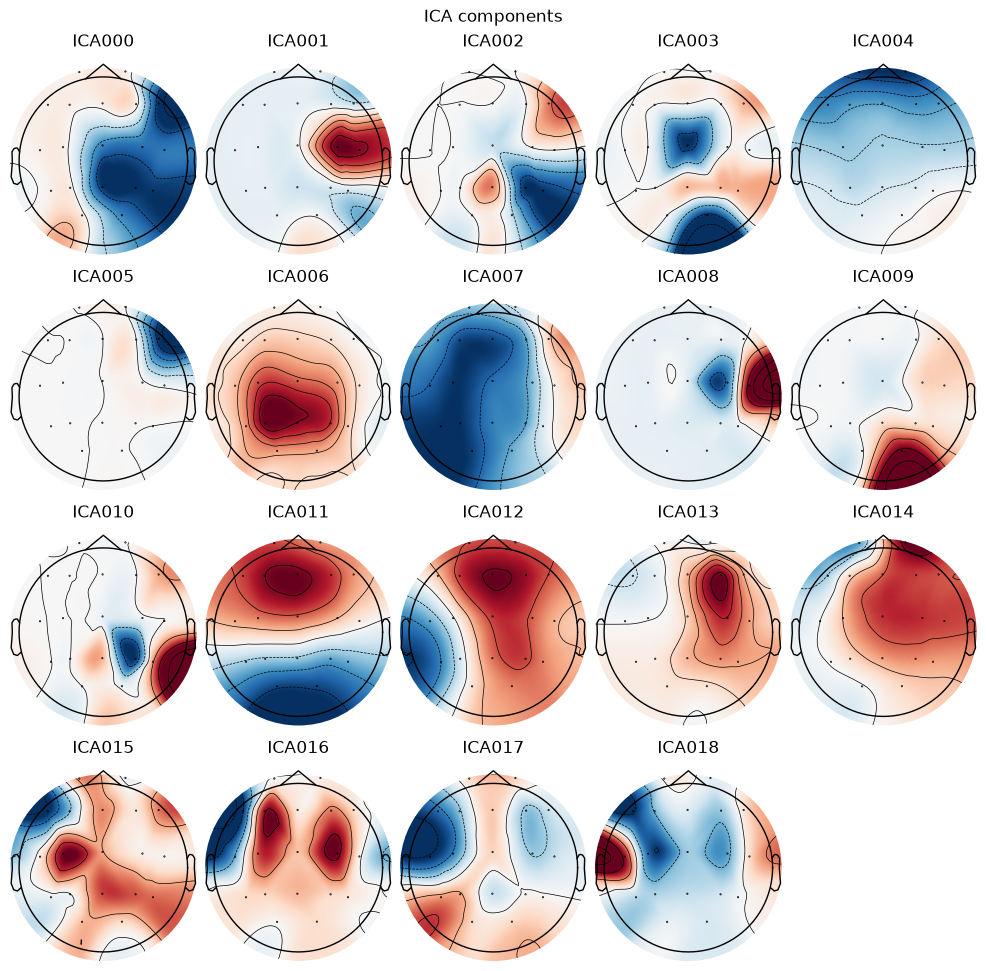

In [50]:
ica_mdd.plot_components()

Creating RawArray with float64 data, n_channels=19, n_times=77568
    Range : 0 ... 77567 =      0.000 ...   302.996 secs
Ready.


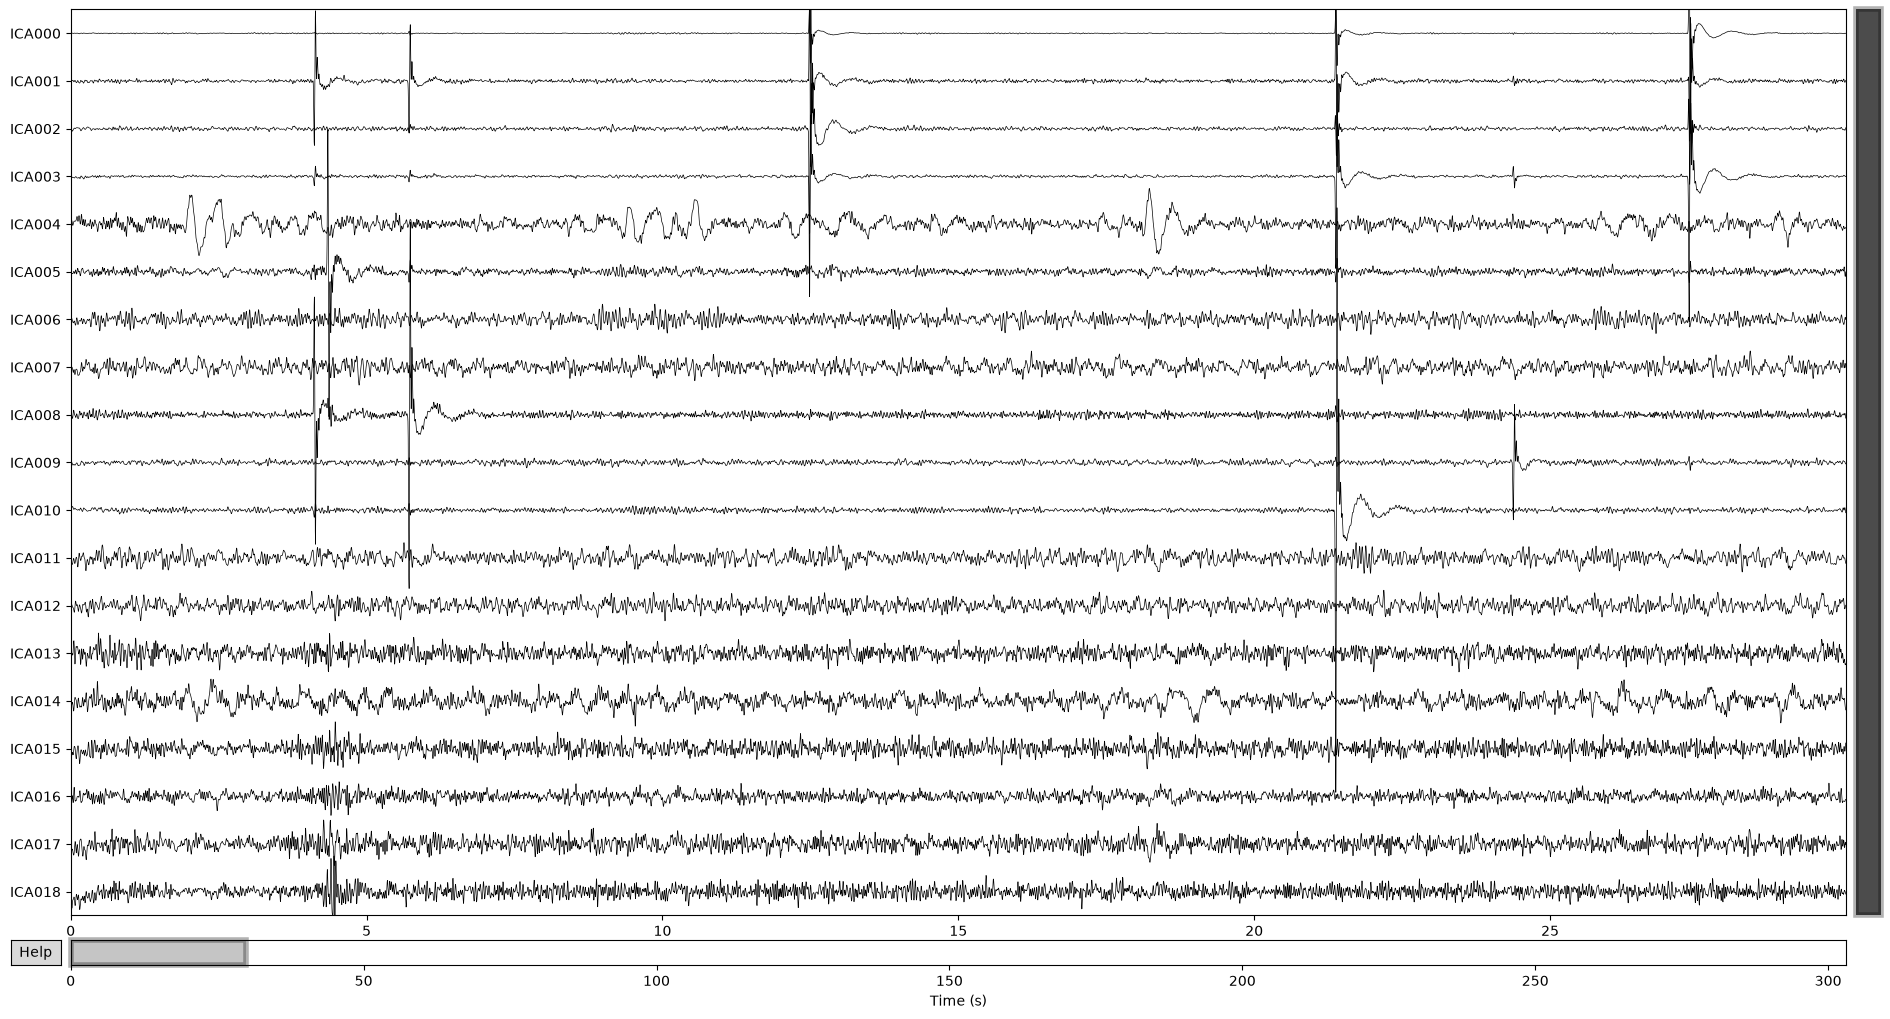

In [51]:
ica_mdd.plot_sources(
    raw_mdd,
    start=0,
    stop=30
)

In [52]:
# 1. Source shape
ica_sources = ica_mdd.get_sources(raw_mdd)
ica_data = ica_sources.get_data()

print("ICA source shape:", ica_data.shape)


# 2. Component amplitudes
component_ptp = np.ptp(ica_data, axis=1)

for i in np.argsort(component_ptp)[::-1]:
    print(
        f"IC {i:02d}: "
        f"{component_ptp[i] * 1e6:.2f} µV"
    )


# 3. Properties of the largest/suspicious components

ICA source shape: (19, 77568)
IC 10: 122593714.76 µV
IC 05: 108205451.39 µV
IC 09: 93612207.31 µV
IC 00: 90384808.29 µV
IC 02: 78202111.07 µV
IC 08: 76877974.05 µV
IC 03: 74204554.83 µV
IC 01: 68031683.37 µV
IC 16: 47656354.81 µV
IC 18: 39490958.76 µV
IC 15: 38541929.92 µV
IC 17: 32307854.73 µV
IC 13: 31269759.44 µV
IC 07: 23652569.65 µV
IC 04: 21362401.92 µV
IC 12: 17902622.26 µV
IC 14: 12043586.48 µV
IC 06: 10119952.04 µV
IC 11: 9104466.91 µV


In [53]:
ica_mdd.plot_properties(
    raw_mdd,
    picks=[0, 1, 2, 3, 5, 8, 9, 10]
)

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
151 matching events found
No baseline correction applied
0 projection items activated


[<Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>]